# Reaching the Ridge solution with fixed features

**The claim being tested.** A random-feature model, with no feature learning anywhere, trained by
one-pass SGD on in-context linear regression, lands essentially on the **Ridge** (generalizing,
Bayes-under-the-prior) solution, while the **dMMSE** (memorizing, Bayes-under-the-pool) solution
stays far away -- at a task diversity T small enough that the two are very different.

**Why it is reachable here.** Three things are arranged so the only gap left is the one we can
afford to shrink:

1. **The kernel carries the target's exact symmetries.** The Bayes predictor is
   $\hat\beta(X,y)\cdot x_q$: linear in the query, and even in the context under a joint sign flip.
   The kernel is $k_{\mathrm{even}}(c,c')\,(x_q\cdot x_q')$ with $c=[X,y]$, whose random features are
   phase-free cosines times the query. Modes outside that span carry **zero** target power, so this
   costs no expressiveness and cuts the features needed for the degree-3 channel by ~100x.
2. **The pool has its finite-sample artifacts removed.** `whiten_zeromean_tr1` gives
   $\hat\Sigma=I$, $\hat\mu=0$ and $\mathrm{Tr}_1[\hat\kappa_3]=0$ -- exactly the pool statistics the
   degree-3 channels can see. The degree-3 floor then equals its Gaussian-prior value at **every** T,
   and the q and $y^2q$ channels carry nothing: the whole solution is the $Xyq$ channel, i.e.
   optimally scaled one-step GD.
3. **The context is long.** The degree-3 truncation of Ridge has a gap that scales as
   $(d+1)/L$ of the available range, so $L \gg d$ makes it small. At d=3 with 96 pairs it is ~4%.

**What the numbers should be** (d=3, 96 pairs, $\sigma_x^2=1/d$, $\epsilon^2=0.05$): Ridge 0.049,
the model's floor 0.087, dMMSE 0.666 at T=4 and 0.490 at T=8. So the model should sit ~1.8x above
Ridge in absolute error while dMMSE sits ~13x above it, with ID and OOD on top of each other.

**What this does not show.** The gap to Ridge is a truncation gap, not a failure to generalize: it
shrinks like $1/L$ and would need L ~ 45d to vanish, which costs $L^4$ in compute. And the symmetries
above are given to the model rather than learned -- the honest claim is "fixed random features, given
the problem's symmetries, reach Ridge", not "reach it from raw tokens".

## Colab setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import sys, os

GIT_USER = "JoeyTurn"
GIT_REPO = "kernels_can_icl"

!git clone https://github.com/{GIT_USER}/{GIT_REPO}.git

sys.path.insert(0, "/content/kernels_can_icl")
sys.path.insert(0, "/content/kernels_can_icl/expts/rf_scaling")

RESULTPATH = "/content/drive/MyDrive/results"
os.environ["RESULTPATH"] = RESULTPATH
os.makedirs(RESULTPATH, exist_ok=True)

Mounted at /content/drive
GitHub PAT: ··········
Cloning into 'kernel_ICL'...
remote: Enumerating objects: 940, done.
remote: Counting objects: 100% (475/475), done.
remote: Compressing objects: 100% (320/320), done.
remote: Total 940 (delta 294), reused 331 (delta 150), pack-reused 465 (from 1)
Receiving objects: 100% (940/940), 56.03 MiB | 43.40 MiB/s, done.
Resolving deltas: 100% (488/488), done.


In [ ]:
import os, sys, math, time, pickle, dataclasses
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

if not os.path.exists("/content/kernels_can_icl"):
    ROOT = Path.cwd()
    while ROOT != ROOT.parent and not (ROOT / "kernels_can_icl" / "__init__.py").exists():
        ROOT = ROOT.parent
    sys.path.insert(0, str(ROOT))
    sys.path.insert(0, str(ROOT / "expts" / "rf_scaling"))
    RESULTPATH = str(ROOT / "expts" / "rf_scaling" / "results")
    os.makedirs(RESULTPATH, exist_ok=True)

import kicl_floor as KF
import transience_utils as TU
import structured_rf as SR

# A stale clone pairs this notebook with older modules; fail here, not an hour in.
_missing = [n for n in ("StructuredRF", "StructuredSpectrum", "context_of") if not hasattr(SR, n)]
if "whiten_zeromean_tr1" not in open(KF.__file__, encoding="utf-8").read():
    _missing.append("kicl_floor pool kind whiten_zeromean_tr1")
if _missing:
    raise RuntimeError(f"stale clone (missing {_missing}). Run `!git -C /content/kernels_can_icl pull`, "
                       "then Runtime > Restart.")

torch.backends.cuda.matmul.allow_tf32 = False     # the faint channels are ~1e-5 of the top mode
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GPU_GB = torch.cuda.get_device_properties(0).total_memory / 1e9 if DEVICE.type == "cuda" else 0.0
print("device:", DEVICE, f"({torch.cuda.get_device_name(0)}, {GPU_GB:.1f} GB)" if GPU_GB
      else "(CPU -- runs the RR_SMOKE version)")

device: cuda (NVIDIA A100-SXM4-40GB, 42.4 GB)


## Configuration

d=3 with 96 pairs is the affordable point on the (d+1)/L curve: the degree-3 floor is 4% of the
range above Ridge. Cost scales as $L^4$, so 192 pairs (2.2%) is ~16x this and 384 pairs is out.

T=4 is the largest separation from dMMSE (16x) and, being $T=d+1$, its pool is a regular simplex,
for which $\mathrm{Tr}_1[\hat\kappa_3]=0$ holds automatically. The rest of the sweep shows dMMSE
closing in as the pool fills while the model's level does not move. T < d+1 is excluded: the
zero-mean whitened pool would be rank-limited, leaving task directions unidentifiable.

`RR_SMOKE=1` (automatic on CPU) runs a tiny version end to end in a few minutes.

In [ ]:
SMOKE = bool(int(os.environ.get("RR_SMOKE", "0"))) or DEVICE.type != "cuda"

DIM, PAIRS, EPS = 3, 96, 0.05          # sigma_x^2 = 1/d; the long context makes the truncation tight
CFG = KF.make_config(DIM, PAIRS, EPS)
assert (CFG.dim, CFG.L, CFG.e) == (DIM, PAIRS, EPS), "stale kicl_floor.py -- git pull and restart"

POOL_KIND    = "whiten_zeromean_tr1"   # Sigma_hat = I, mu_hat = 0, Tr_1[kappa_3] = 0
WIDTH_FACTOR = 1.5                     # x median||c - c'|| over CONTEXT vectors
SEED         = 0
LR_FRAC      = 0.8                     # eta = LR_FRAC * 2 / lambda_1 (measured on the real operator)
TARGET_FAMILY = "Xy"                   # the only degree-3 channel with target power under this pool
TARGET_L     = 0.9                     # train until it reaches this (or the M-feature ceiling)
CKPT_SECONDS = 600

if SMOKE:
    T_LIST, TRIALS = [4, 8], 1
    DIM, PAIRS = 3, 12
    CFG = KF.make_config(DIM, PAIRS, EPS)
    M_FEATURES, BATCH, TEST_SZ = 4_096, 64, 2_048
    SMOKE_STEPS = 1_500
else:
    T_LIST   = [4]#[4, 8, 16, 32, 64]      # T >= d+1 keeps the whitened zero-mean pool full rank
    TRIALS   = 3
    M_FEATURES = "auto"                # context features; the readout is M x d
    BATCH, TEST_SZ = 256, 65_536       # the gap to Ridge is ~0.04: keep the test error well under it
    SMOKE_STEPS = None
CURVE_TS = T_LIST
N_EVAL, EVAL_CHUNK = 40, 128

print(CFG.describe())
print(f"SMOKE={SMOKE}  M={M_FEATURES}  batch={BATCH}  T={T_LIST}  trials={TRIALS}")

d3 96pairs eps0.05: d=3 L_cfg=97 (L=96 pairs) e=0.05 v=0.33333 sigma_beta2=1.0 D=387 norm2=1.05000
SMOKE=False  M=auto  batch=256  T=[4]  trials=3


## Width, sizing and what to expect

The kernel acts on the context $c=[X,y]$ only, so the width is calibrated on context vectors. The
sizing ladder is relative to the context constant mode; the absolute scale comes from the measured
$\lambda_1$, so nothing here depends on a normalization convention.

The table printed below is the whole experiment in advance: the floor the model should reach, Ridge,
and dMMSE at each T.

In [ ]:
_td, _ = TU.make_pool_distr(CFG, 8, SEED, POOL_KIND, DEVICE)
_, _, _Xc, _yc, _Xq = TU.gen_raw(_td, CFG, 3000, "pretrain")
_C = SR.context_of(_Xc, _yc)
MEDIAN_CTX = float(torch.cdist(_C[:1500].double(), _C[1500:].double()).flatten().median())
WIDTH = WIDTH_FACTOR * MEDIAN_CTX
D_CTX = _C.shape[1]
SPEC = SR.StructuredSpectrum(CFG, WIDTH)
print(f"D_ctx = {D_CTX}   median||c - c'|| = {MEDIAN_CTX:.3f}   width = {WIDTH:.3f} ({WIDTH_FACTOR}x)")

# features: one power of 2 above what the target channel needs, capped by memory
_per_feature = 4 * (D_CTX + BATCH + EVAL_CHUNK) + 8 * DIM
if M_FEATURES == "auto":
    M_FEATURES = 2 ** math.ceil(math.log2(SPEC.M_for(TARGET_FAMILY, TARGET_L)))
    if GPU_GB and M_FEATURES * _per_feature > 0.4 * GPU_GB * 1e9:
        M_FEATURES = 2 ** int(math.log2(0.4 * GPU_GB * 1e9 / _per_feature))
        print(f"capped by memory: M = {M_FEATURES:,}")
L_CEIL = SPEC.L_ceiling(TARGET_FAMILY, M_FEATURES)

_model = SR.StructuredRF(M_FEATURES, D_CTX, DIM, WIDTH, SEED, DEVICE)
LAM1 = _model.top_eigenvalue(_C[:512].to(DEVICE), _Xq[:512].squeeze(1).to(DEVICE))
ETA = LR_FRAC * 2.0 / LAM1
MAX_STEPS = int(math.ceil(SPEC.steps_for(TARGET_FAMILY, ETA, LAM1, min(TARGET_L, 0.999 * L_CEIL))))
EVAL_STEPS = sorted({max(1, int(round(s))) for s in np.geomspace(1, MAX_STEPS, N_EVAL)})
del _model

print(f"M = {M_FEATURES:,} context features ({M_FEATURES * DIM:,} parameters), "
      f"~{M_FEATURES * _per_feature / 1e9:.1f} GB")
print(f"lambda_1 {LAM1:.4f} -> eta {ETA:.2f};  {TARGET_FAMILY} ceiling at this M: {L_CEIL:.3f}; "
      f"MAX_STEPS {MAX_STEPS:,} (n_seen {MAX_STEPS * BATCH:,})")
print(f"\n{'channel':>8} {'lambda/lam1':>12} {'M for L=.9':>12} {'ceiling here':>13} {'steps':>12}")
for row in SPEC.describe(M_FEATURES, ETA, LAM1):
    print(f"{row[0]:>8} {row[1]:>12} {row[2]:>12} {row[3]:>13} {row[4] if len(row) > 4 else '':>12}")

D_ctx = 384   median||c - c'|| = 19.785   width = 29.678 (1.5x)
M = 65,536 context features (196,608 parameters), ~0.2 GB
lambda_1 0.2891 -> eta 5.53;  Xy ceiling at this M: 0.921; MAX_STEPS 3,199,770 (n_seen 819,141,120)

 channel  lambda/lam1   M for L=.9  ceiling here        steps
       q    1.000e+00            1         1.000            1
      y2    1.414e-06       45,179         0.974    1,017,450
      Xy    4.498e-07       62,334         0.921    3,199,770
      XX    1.430e-07       75,410         0.788    6,761,412
     y3X    6.361e-13  438,954,937         0.000   16,221,190
    y2XX    2.023e-13  654,160,179         0.000   16,221,282


In [ ]:
# What the run should produce, before running it.
_pre3 = KF.build_floor_engine(CFG, (3,))[3]
_s, _e, _d = CFG.v, CFG.e, CFG.dim
WALL = (_s * _d * (_d + 1 + _e / _s) / (CFG.L + _d + 1 + _e / _s) + _e) / (_s * _d + _e)
print(f"degree-3 floor (closed form, one-step GD): {WALL:.4f}")
print(f"{'T':>4} {'floor3 OOD':>11} {'floor3 ID':>10} {'Ridge':>8} {'dMMSE':>8} | {'floor-Ridge':>11} "
      f"{'dMMSE-Ridge':>11} {'further':>8}")
for _T in T_LIST:
    _f, _o = [], []
    for _t in range(TRIALS):
        _seed = SEED + 1009 * _t + 17 * _T
        torch.manual_seed(_seed)
        _b = KF.draw_betas(_T, CFG, POOL_KIND, torch.device("cpu"))
        _f.append(KF.ood_floors_fast(_pre3, _b, CFG.sigma_beta2))
        _o.append(KF.oracle_mse_one_betas(_b, DIM, CFG.L_cfg, CFG.v, CFG.e, 1.0, CFG.norm2, 4000,
                                          np.random.default_rng(_t)))
    _fi, _fo = np.mean(_f, 0)
    _rg = float(np.mean([o["ridge_ood"] for o in _o])); _dm = float(np.mean([o["dmmse_ood"] for o in _o]))
    print(f"{_T:>4} {_fo:>11.4f} {_fi:>10.4f} {_rg:>8.4f} {_dm:>8.4f} | {_fo - _rg:>11.4f} "
          f"{_dm - _rg:>11.4f} {(_dm - _rg) / (_fo - _rg):>7.1f}x")

degree-3 floor (closed form, one-step GD): 0.0871
   T  floor3 OOD  floor3 ID    Ridge    dMMSE | floor-Ridge dMMSE-Ridge  further
   4      0.0871     0.0871   0.0490   0.6555 |      0.0381      0.6065    15.9x


In [ ]:
def estimate_runtime():
    m = SR.StructuredRF(M_FEATURES, D_CTX, DIM, WIDTH, 0, DEVICE)
    td, _ = TU.make_pool_distr(CFG, 8, SEED, POOL_KIND, DEVICE)
    _, yq, Xc, yc, Xq = TU.gen_raw(td, CFG, BATCH, "pretrain")
    C, xq = SR.context_of(Xc, yc), Xq.squeeze(1)
    sync = torch.cuda.synchronize if DEVICE.type == "cuda" else (lambda: None)
    for _ in range(3):
        m.step(C, xq, yq, ETA)
    sync(); t0 = time.time()
    for _ in range(10):
        m.step(C, xq, yq, ETA)
    sync()
    per = (time.time() - t0) / 10
    del m
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    runs = len(T_LIST) * TRIALS
    print(f"{per * 1e3:.1f} ms/step -> {MAX_STEPS * per / 60:.0f} min per run x {runs} runs = "
          f"{runs * MAX_STEPS * per / 3600:.1f} h (evaluation extra, ~{2 * TEST_SZ / BATCH * per * N_EVAL / 60:.0f} min/run)")

estimate_runtime()

1.4 ms/step -> 74 min per run x 3 runs = 3.7 h (evaluation extra, ~0 min/run)


## The runs

One run per (T, trial): fresh pool, fresh feature draw, one-pass SGD on a stream that never repeats a
sample. Each run checkpoints every `CKPT_SECONDS` to its own file and re-running this cell resumes.
`MAX_STEPS` is deliberately not in the fingerprint, so raising `TARGET_L` extends a run instead of
restarting it.

In [ ]:
TAG = f"d{DIM}p{PAIRS}e{EPS:g}_M{M_FEATURES}_b{BATCH}_w{WIDTH_FACTOR}{'_smoke' if SMOKE else ''}"
PRE3 = KF.build_floor_engine(CFG, (3,))[3]

def ckpt_path(T, trial):
    return os.path.join(RESULTPATH, f"rf_ridge_reach_{TAG}_T{T}_t{trial}.pt")

def _fingerprint(T, trial, seed):
    return dict(dim=DIM, pairs=PAIRS, M=M_FEATURES, batch=BATCH, width=round(WIDTH, 6), T=T,
                pool=POOL_KIND, eps=CFG.e, test_sz=TEST_SZ, seed=seed)

def _same(got, fp):
    approx = {"width", "eta"}
    return (isinstance(got, dict) and set(got) == set(fp)
            and all(math.isclose(got[k], fp[k], rel_tol=1e-3) if k in approx else got[k] == fp[k] for k in fp))

def save_ckpt(path, obj, attempts=4):
    for i in range(attempts):
        try:
            torch.save(obj, path + ".tmp")
            os.replace(path + ".tmp", path)
            return True
        except Exception as err:
            print(f"   checkpoint write failed ({err}); retry {i + 1}")
            time.sleep(2 + 3 * i)
    return False

def train_run(T, trial):
    seed = SEED + 1009 * trial + 17 * T
    path, fp = ckpt_path(T, trial), _fingerprint(T, trial, seed)
    td, betas = TU.make_pool_distr(CFG, T, seed, POOL_KIND, DEVICE)
    tests = TU.make_tests(td, CFG, {"id": (TEST_SZ, "pretrain"), "ood": (TEST_SZ, "true")}, seed)
    ctx = {k: (SR.context_of(v["Xc"], v["yc"]), v["Xq"].squeeze(1)) for k, v in tests.items()}
    model = SR.StructuredRF(M_FEATURES, D_CTX, DIM, WIDTH, seed, DEVICE)

    st = torch.load(path, map_location="cpu", weights_only=False) if os.path.exists(path) else None
    if st is not None and not _same(st.get("fingerprint"), fp):
        print("   checkpoint is from a different configuration; starting over")
        st = None
    if st is not None:
        model.load(st); start, curve, ref = int(st["step"]), list(st["curve"]), st["ref"]
        if start >= MAX_STEPS:
            print(f"T={T:>3} trial {trial}: complete ({start:,} steps)")
            return dict(T=T, trial=trial, seed=seed, curve=curve, **ref)
        print(f"T={T:>3} trial {trial}: resuming at step {start:,} of {MAX_STEPS:,}")
    else:
        fl = KF.ood_floors_fast(PRE3, betas, CFG.sigma_beta2)
        orc = {}
        for side in ("id", "ood"):
            pr, pd_ = TU.oracle_preds(tests[side]["Xc"], tests[side]["yc"], tests[side]["Xq"], betas, CFG)
            orc[f"ridge_{side}"] = TU.nmse(pr, tests[side]["y"], CFG)
            orc[f"dmmse_{side}"] = TU.nmse(pd_, tests[side]["y"], CFG)
        ref = dict(floor3=dict(id=float(fl[0]), ood=float(fl[1])), oracles=orc, betas=betas)
        start, curve = 0, []
        print(f"T={T:>3} trial {trial}: fresh. floor3 OOD {fl[1]:.4f}  Ridge {orc['ridge_ood']:.4f}  "
              f"dMMSE {orc['dmmse_ood']:.4f}")

    def evaluate(step):
        row = dict(step=step, n=step * BATCH)
        for side in ("id", "ood"):
            p = model.predict(*ctx[side], chunk=EVAL_CHUNK)
            row[side], row[f"{side}_se"] = TU.nmse_se(p, tests[side]["y"], CFG)
        return row

    stop = MAX_STEPS if SMOKE_STEPS is None else min(MAX_STEPS, SMOKE_STEPS)
    t_ck = time.time()
    for step in range(start + 1, stop + 1):
        _, yq, Xc, yc, Xq = TU.gen_raw(td, CFG, BATCH, "pretrain")
        model.step(SR.context_of(Xc, yc), Xq.squeeze(1), yq, ETA)
        if step in EVAL_STEPS or step == stop:
            row = evaluate(step)
            curve.append(row)
            print(f"   step {step:>9,}  n_seen {step * BATCH:>12,}  ID {row['id']:.4f}  OOD {row['ood']:.4f}")
        if time.time() - t_ck > CKPT_SECONDS or step == stop:
            save_ckpt(path, dict(fingerprint=fp, step=step, curve=curve, ref=ref, **model.state()))
            t_ck = time.time()
    return dict(T=T, trial=trial, seed=seed, curve=curve, **ref)

records = []
t_all = time.time()
for trial in range(TRIALS):
    for T in T_LIST:
        records.append(train_run(T, trial))
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
SUMMARY = os.path.join(RESULTPATH, f"rf_ridge_reach_{TAG}_summary.pkl")
with open(SUMMARY, "wb") as f:
    pickle.dump(dict(records=records, config=dataclasses.asdict(CFG), dim=DIM, pairs=PAIRS,
                     M=M_FEATURES, batch=BATCH, width=WIDTH, eta=ETA, lam1=LAM1, max_steps=MAX_STEPS,
                     pool=POOL_KIND, wall=WALL), f)
print(f"\ndone in {(time.time() - t_all) / 60:.1f} min -> {SUMMARY}")

T=  4 trial 0: fresh. floor3 OOD 0.0871  Ridge 0.0494  dMMSE 0.6547
   step         1  n_seen          256  ID 1.1629  OOD 1.1806
   step         2  n_seen          512  ID 1.0016  OOD 1.0148
   step         3  n_seen          768  ID 1.0095  OOD 1.0218
   step         5  n_seen        1,280  ID 1.0061  OOD 1.0187
   step         7  n_seen        1,792  ID 1.0006  OOD 1.0139
   step        10  n_seen        2,560  ID 1.0626  OOD 1.0772
   step        15  n_seen        3,840  ID 0.9982  OOD 1.0112
   step        22  n_seen        5,632  ID 1.0379  OOD 1.0510
   step        32  n_seen        8,192  ID 1.0391  OOD 1.0522
   step        47  n_seen       12,032  ID 1.1443  OOD 1.1546
   step        68  n_seen       17,408  ID 0.9969  OOD 1.0110
   step       100  n_seen       25,600  ID 1.0550  OOD 1.0713
   step       147  n_seen       37,632  ID 0.9954  OOD 1.0093
   step       216  n_seen       55,296  ID 1.0288  OOD 1.0448
   step       318  n_seen       81,408  ID 1.0057  OOD 1.0183
  

KeyboardInterrupt: 

## Result

Linear axis, because the point is how small the remaining gap to Ridge is against the range the task
offers. ID and OOD are drawn together: under this pool they should coincide, which is the statement
that the model generalizes rather than memorizes.

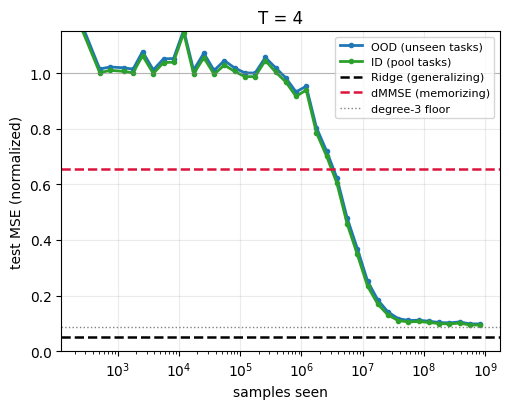

In [ ]:
def curves(T, side):
    rs = [r for r in records if r["T"] == T]
    ns = sorted({c["n"] for r in rs for c in r["curve"]})
    m = np.array([[np.mean([c[side] for c in r["curve"] if c["n"] == n] or [np.nan]) for n in ns] for r in rs])
    return np.array(ns, float), np.nanmean(m, 0), (np.nanstd(m, 0) if len(rs) > 1 else np.zeros(len(ns)))

def ref_of(T, key, side):
    rs = [r for r in records if r["T"] == T]
    return float(np.mean([(r["floor3"][side] if key == "floor3" else r["oracles"][f"{key}_{side}"]) for r in rs]))

fig, axs = plt.subplots(1, len(CURVE_TS), figsize=(5.2 * len(CURVE_TS), 4.2), squeeze=False)
for ax, T in zip(axs[0], CURVE_TS):
    for side, col, lab in (("ood", "C0", "OOD (unseen tasks)"), ("id", "C2", "ID (pool tasks)")):
        n, m, s = curves(T, side)
        ax.plot(n, m, "-o", ms=3, lw=2, color=col, label=lab)
        if np.any(s > 0):
            ax.fill_between(n, m - s, m + s, color=col, alpha=0.2)
    ax.axhline(ref_of(T, "ridge", "ood"), color="black", lw=1.8, ls="--", label="Ridge (generalizing)")
    ax.axhline(ref_of(T, "dmmse", "ood"), color="crimson", lw=1.8, ls="--", label="dMMSE (memorizing)")
    ax.axhline(ref_of(T, "floor3", "ood"), color="gray", lw=1.0, ls=":", label="degree-3 floor")
    ax.axhline(1.0, color="gray", lw=0.8, alpha=0.5)
    ax.set_xscale("log"); ax.set_ylim(0, 1.15)
    ax.set_xlabel("samples seen"); ax.set_title(f"T = {T}")
    if T == CURVE_TS[0]:
        ax.set_ylabel("test MSE (normalized)"); ax.legend(fontsize=8, loc="upper right")
    ax.grid(alpha=0.25)
# fig.suptitle(f"{CFG.describe()}  |  M={M_FEATURES:,} context features, w={WIDTH_FACTOR}x median", fontsize=9)
fig.tight_layout()
FIGDIR = os.path.join(RESULTPATH, "figs"); os.makedirs(FIGDIR, exist_ok=True)
fig.savefig(os.path.join(FIGDIR, f"rf_ridge_reach_{TAG}.pdf"), dpi=130, bbox_inches="tight")
plt.show()

In [ ]:
print(f"{'T':>4} | {'final OOD':>10} {'final ID':>9} | {'Ridge':>7} {'dMMSE':>7} {'floor3':>7} | "
      f"{'OOD-Ridge':>10} {'dMMSE-Ridge':>12} {'further':>8} {'% of range':>11}")
for T in T_LIST:
    rs = [r for r in records if r["T"] == T]
    fo = np.mean([r["curve"][-1]["ood"] for r in rs]); fi = np.mean([r["curve"][-1]["id"] for r in rs])
    sd = np.std([r["curve"][-1]["ood"] for r in rs])
    rg, dm, f3 = (ref_of(T, k, "ood") for k in ("ridge", "dmmse", "floor3"))
    print(f"{T:>4} | {fo:>10.4f} {fi:>9.4f} | {rg:>7.4f} {dm:>7.4f} {f3:>7.4f} | {fo - rg:>+10.4f} "
          f"{dm - rg:>+12.4f} {(dm - rg) / (fo - rg):>7.1f}x {(fo - rg) / (1 - rg):>10.1%}")
print("\n'further' = how many times further from Ridge the memorizing solution is than the model.")
print("'% of range' = the model's remaining gap to Ridge, as a fraction of null (1.0) minus Ridge.")

   T |  final OOD  final ID |   Ridge   dMMSE  floor3 |  OOD-Ridge  dMMSE-Ridge  further  % of range
   4 |     0.0978    0.0941 |  0.0494  0.6547  0.0871 |    +0.0484      +0.6053    12.5x       5.1%

'further' = how many times further from Ridge the memorizing solution is than the model.
'% of range' = the model's remaining gap to Ridge, as a fraction of null (1.0) minus Ridge.
